# Full-catalog similarity map: coverage, projections and fidelity

All 24,297 catalog problems (LeetCode, Codeforces, AtCoder) embedded from their **titles only** with the
pinned `all-MiniLM-L6-v2`. Scores and positions describe how alike titles read. They do not establish that
two problems share an algorithm. Platform tags and the AI-reviewed taxonomy are separate evidence that never
influenced the vectors, neighbors or coordinates. This notebook is aggregate-only: no problem titles, tags
or statements are printed.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
RUN = ROOT / "private-learning/unified-map/full-v1"
REC = ROOT / "research/unified_map/full-receipts"
FIG = ROOT / "research/unified_map/figures"
FIG.mkdir(exist_ok=True)
emb = json.loads((REC / "embeddings.v1.json").read_text())
qual = json.loads((REC / "quality.v1.json").read_text())
PLAT = ["atcoder", "codeforces", "leetcode"]
COLORS = {"atcoder": "#009E73", "codeforces": "#0072B2", "leetcode": "#E69F00"}
print("nodes:", emb["nodes"], "| vectors reused:", emb["vectors"]["reused_a1"],
      "| newly encoded:", emb["vectors"]["new_title_encode"])

nodes: 24297 | vectors reused: 21297 | newly encoded: 3000


## 1. Embedding coverage
The earlier map had compatible vectors for 21,297 of 24,297 nodes. The gap was closed by encoding only the missing titles with the same pinned model and settings; the reused vectors were re-checked.

In [2]:
cov = pd.DataFrame(emb["coverage_before"])
cov["group"] = np.where(cov.had_a1_vector, "had A1 vector", "missing before")
display(cov.pivot_table(index=["platform", "eligibility", "non_latin_title"], columns="group",
                        values="rows", aggfunc="sum", fill_value=0))
rel = emb["reliability"]
print("reliability tiers:", rel["counts"], "| thresholds:", rel["thresholds"])
print("reuse check:", emb["reuse_check"])

group                                   had A1 vector  missing before
platform   eligibility non_latin_title                               
atcoder    eligible    False                     7467               0
                       True                         0            2141
           excluded    False                        0             102
                       True                         0              77
codeforces eligible    False                    10881               0
                       True                         0              16
           excluded    False                        0             534
                       True                         0              26
leetcode   eligible    False                     2949               0
           excluded    False                        0             104

reliability tiers: {'degraded': 1684, 'reliable': 22030, 'unreliable': 583} | thresholds: {'degraded_unk_share': 0.1, 'non_latin_title_cap': 'degraded', 'unreliable_unk_share': 0.5}
reuse check: {'interpretation': 're-encoding sampled A1 titles in a different batch composition', 'max_abs_component_deviation': 1.825392246246338e-07, 'min_cosine_to_stored': 0.9999997615814209, 'sample_size': 500, 'seed': 17}


**Reading the table.** Non-Latin titles (mostly Japanese AtCoder) are embedded by an English-only model. They are never labelled `reliable`: a non-Latin title is capped at `degraded`, and a title with at least half unknown tokens is `unreliable`. These flags travel with every node into the interactive map.

## 2. Full-catalog projections (all 24,297 nodes)

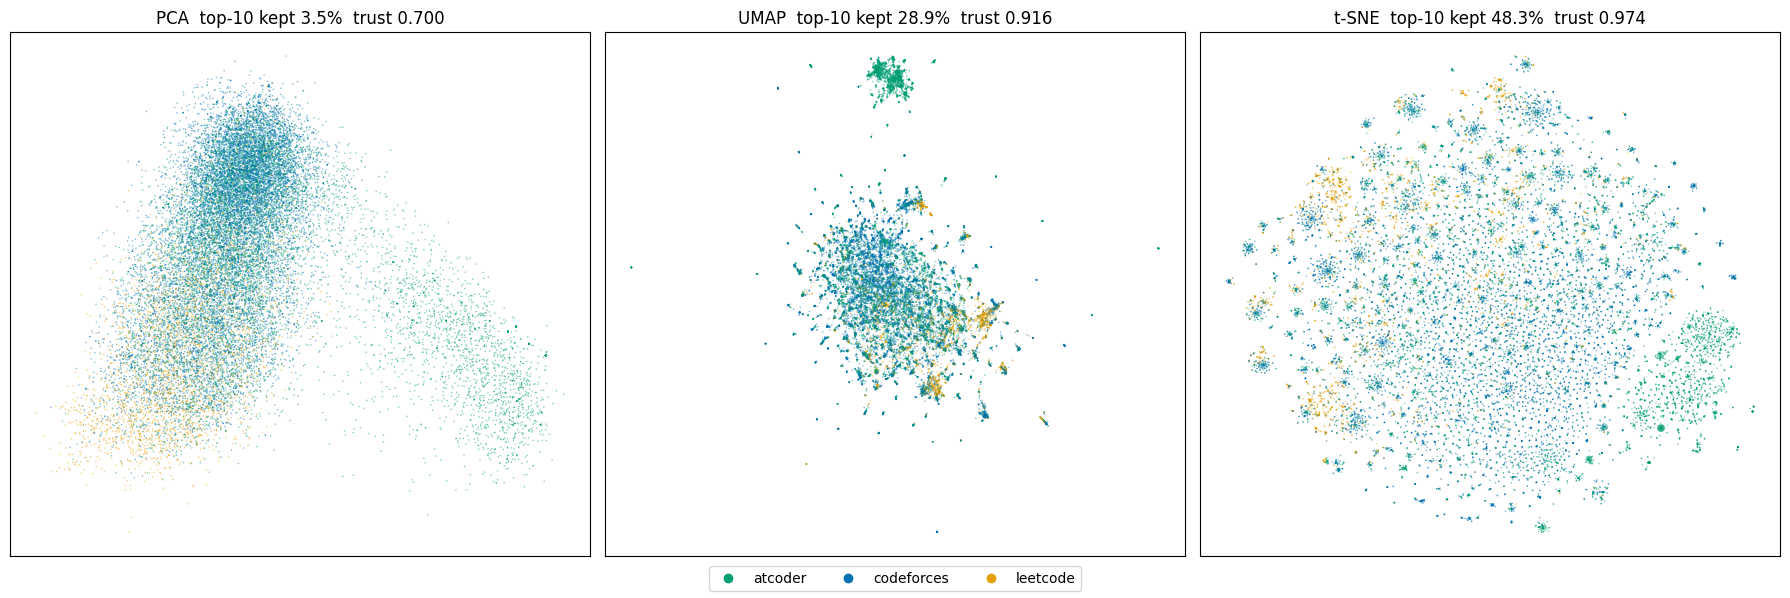

Colour = platform only. Positions use title vectors; no tag or algorithm information.


In [3]:
keys = json.loads((RUN / "keys.json").read_text())
nodes = {}
for line in (ROOT / "private-learning/unified-map/map-v2/nodes.jsonl").read_text().splitlines():
    n = json.loads(line); nodes[n["problem_key"]] = n["platform"]
plat = np.array([PLAT.index(nodes[k]) for k in keys])
proj = {m: np.load(RUN / "projections" / f"{m}-seed17.npy") for m in ("pca", "umap", "tsne")}
names = {"pca": "PCA", "umap": "UMAP", "tsne": "t-SNE"}
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
rng = np.random.default_rng(0)
order = rng.permutation(len(keys))          # fixed shuffle so no platform hides the others
for ax, m in zip(axes, proj):
    xy = proj[m]
    ax.scatter(xy[order, 0], xy[order, 1], s=1.2, alpha=0.5, linewidths=0,
               c=[COLORS[PLAT[p]] for p in plat[order]])
    q = qual["projections"][m + "-seed17"]
    ax.set_title(f"{names[m]}  top-10 kept {q['preservation_top10_any']:.1%}  trust {q['trustworthiness']:.3f}")
    ax.set_xticks([]); ax.set_yticks([])
handles = [plt.Line2D([], [], marker="o", ls="", color=COLORS[p], label=p) for p in PLAT]
fig.legend(handles=handles, loc="lower center", ncol=3)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG / "full-projections.png", dpi=110)
plt.show()
print("Colour = platform only. Positions use title vectors; no tag or algorithm information.")

## 3. Projection fidelity against exact 384-d neighbors

,top10_kept_any,top10_kept_cross_platform,trustworthiness,continuity,same_platform_top10
projection,,,,,
pca-seed17,0.035,0.027,0.700,0.840,0.507
tsne-random-seed18,0.482,0.353,0.974,0.931,0.592
tsne-random-seed19,0.482,0.355,0.974,0.932,0.594
tsne-seed17,0.483,0.356,0.974,0.931,0.594
tsne-seed18,0.483,0.356,0.974,0.931,0.594
umap-seed17,0.289,0.247,0.916,0.935,0.568
umap-seed18,0.292,0.244,0.914,0.932,0.566
umap-seed19,0.289,0.245,0.916,0.932,0.573


384-d same-platform share of top-10: 0.602 | expected if platforms were unrelated to titles: 0.4


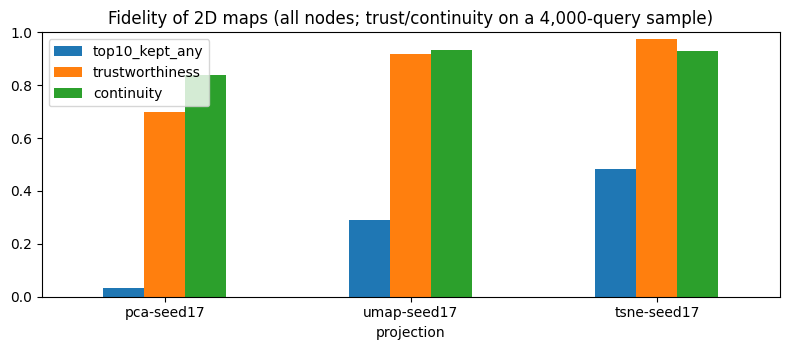

In [4]:
rows = []
for name, e in qual["projections"].items():
    rows.append({"projection": name, "top10_kept_any": e["preservation_top10_any"],
                 "top10_kept_cross_platform": e["preservation_top10_cross_platform"],
                 "trustworthiness": e["trustworthiness"], "continuity": e["continuity"],
                 "same_platform_top10": e["same_platform_fraction_top10"]})
df = pd.DataFrame(rows).set_index("projection")
display(df.style.format("{:.3f}"))
hd = qual["high_dimensional"]
print("384-d same-platform share of top-10:", round(hd["same_platform_fraction_top10"], 3),
      "| expected if platforms were unrelated to titles:",
      round(sum(v * v for v in qual["platform_share"].values()), 3))
fig, ax = plt.subplots(figsize=(8, 3.6))
main = df.loc[["pca-seed17", "umap-seed17", "tsne-seed17"]]
main[["top10_kept_any", "trustworthiness", "continuity"]].plot.bar(ax=ax, rot=0)
ax.set_ylim(0, 1); ax.set_title("Fidelity of 2D maps (all nodes; trust/continuity on a 4,000-query sample)")
fig.tight_layout(); fig.savefig(FIG / "full-fidelity.png", dpi=110); plt.show()

In [5]:
by = pd.DataFrame({n: {**{"platform:" + k: v for k, v in e["preservation_by_platform"].items()},
                       **{"reliability:" + k: v for k, v in e["preservation_by_reliability"].items()}}
                   for n, e in qual["projections"].items() if n.endswith("seed17")}).T
display(by.style.format("{:.3f}"))
print("Local preservation by query platform and embedding-reliability tier (top-10, any platform).")

,platform:atcoder,platform:codeforces,platform:leetcode,reliability:degraded,reliability:reliable,reliability:unreliable
pca-seed17,0.045,0.031,0.014,0.049,0.029,0.219
tsne-seed17,0.490,0.480,0.469,0.487,0.483,0.471
umap-seed17,0.285,0.295,0.283,0.250,0.293,0.274


Local preservation by query platform and embedding-reliability tier (top-10, any platform).


## 4. Seed stability
`init='pca'` makes scikit-learn's t-SNE independent of the seed, so repeating that seed shows nothing. Random-initialisation runs are the real stability probe.

In [6]:
st = []
for method, entries in qual["stability"].items():
    for e in entries:
        st.append({"method": method, "seeds": tuple(e["seeds"]), "procrustes_disparity": e["procrustes_disparity"],
                   "top10_2d_neighbor_overlap": e["top10_2d_neighbor_overlap"], "identical_layout": e["identical_layout"]})
display(pd.DataFrame(st))

,method,seeds,procrustes_disparity,top10_2d_neighbor_overlap,identical_layout
0,tsne,"(17, 18)",7.872801e-31,1.000000,True
1,tsne-random,"(18, 19)",2.096143e-01,0.716529,False
2,umap,"(17, 18)",6.726920e-01,0.289550,False
3,umap,"(17, 19)",4.917254e-01,0.288451,False
4,umap,"(18, 19)",6.907608e-01,0.285912,False


## 5. Tag agreement (descriptive, not validation)
Share of tagged neighbor slots that share an equivalent, high-confidence taxonomy concept with the query, against a baseline that replaces each neighbor by a random tagged node **of the same platform**. Tags were not used to build vectors, so this is not circular for the title neighbors, but shared broad tags do not prove the same technique.

In [7]:
def line(label, obs, base):
    return {"list": label, "observed": obs["share_with_concept"], "platform_matched_random": base["share_with_concept"],
            "lift": obs["share_with_concept"] / base["share_with_concept"], "tagged_slot_coverage": obs["tagged_slot_coverage"]}
rows = [line("384-d top-10, any platform", hd["tag_agreement_top10"], hd["tag_agreement_top10_platform_matched_random"]),
        line("384-d top-10, other platforms", hd["tag_agreement_cross_platform_top10"],
             hd["tag_agreement_cross_platform_top10_platform_matched_random"])]
for m in ("pca", "umap", "tsne"):
    e = qual["projections"][m + "-seed17"]
    rows.append(line(f"{names[m]} 2D top-10, any platform", e["tag_agreement_top10"], e["tag_agreement_top10_platform_matched_random"]))
display(pd.DataFrame(rows).set_index("list").style.format("{:.3f}"))
print("Coverage is limited: AtCoder has no tags and many LeetCode tags map to no concept.")

,observed,platform_matched_random,lift,tagged_slot_coverage
list,,,,
"384-d top-10, any platform",0.526,0.405,1.301,0.683
"384-d top-10, other platforms",0.339,0.202,1.683,0.229
"PCA 2D top-10, any platform",0.410,0.381,1.077,0.646
"UMAP 2D top-10, any platform",0.502,0.392,1.280,0.684
"t-SNE 2D top-10, any platform",0.522,0.400,1.306,0.696


Coverage is limited: AtCoder has no tags and many LeetCode tags map to no concept.


## 6. Neighbor score distributions

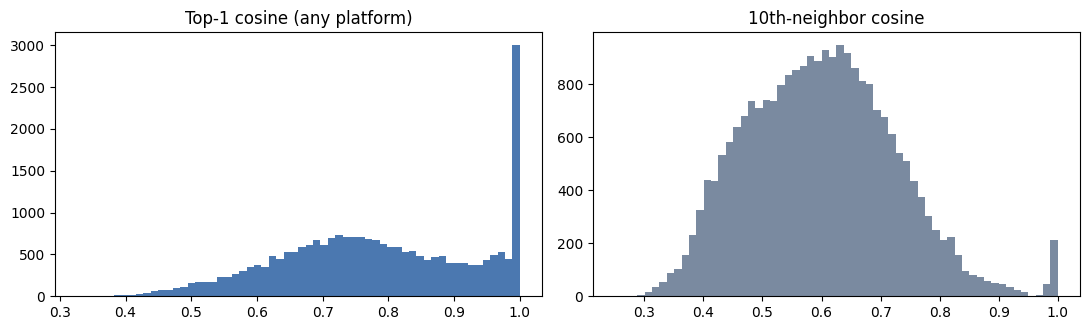

median top-1 0.777, median 10th 0.597; 11.9% of nodes have an exact-title (cosine>=0.999) neighbor


In [8]:
sc = np.load(RUN / "neighbors/any-score.npy")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(sc[:, 0], bins=60, color="#4b78b0"); ax[0].set_title("Top-1 cosine (any platform)")
ax[1].hist(sc[:, 9], bins=60, color="#7a8aa0"); ax[1].set_title("10th-neighbor cosine")
fig.tight_layout(); fig.savefig(FIG / "full-scores.png", dpi=110); plt.show()
print("median top-1 %.3f, median 10th %.3f; %.1f%% of nodes have an exact-title (cosine>=0.999) neighbor"
      % (np.median(sc[:, 0]), np.median(sc[:, 9]), 100 * (sc[:, 0] >= 0.999).mean()))

## Limits

- Title similarity is a weak proxy; generic or narrative titles match by wording.
- 2D maps distort distances. Compare the three projections and the fidelity numbers before reading structure into any of them.
- Non-Latin titles are embedded by an English-only model and are flagged, not trusted.
- Pair judgments cover a small selected set; absence of a judgment is unknown, not negative.
- Nothing here verifies algorithm equivalence, prerequisite direction or learning benefit.